In [ ]:
!pip install torchmetrics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.4 MB/s eta 0:00:00


In [ ]:
!pip install torchinfo -q

In [ ]:
!pip install optuna -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 15.6 MB/s eta 0:00:00


In [ ]:
## import libraries
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchinfo
import optuna # --> Fine tuning model's parameters
## Pytorch's computer vision library
from torchvision import datasets
import torchmetrics
import torchvision.transforms as transforms
import torchvision.transforms.v2 as T
from torch.utils.data import DataLoader
## Results are reproducible
torch.manual_seed(42)
print('code run above successfully')

code run above successfully


In [ ]:
## Normalization of data and preprocessing
transform = transforms.Compose([T.ToImage(),T.ToDtype(torch.float32 , scale = True)]) # --> T.ToTensor is deprecated do preferred to use ToImage

## Data is from MNIST database : contains thousands of images of handwritten didgits
train_data_and_validation_data = torchvision.datasets.MNIST(
    root = '/content/sample_data/train_data_and_validation_data' , train = True , download = True ,  transform = transform
)
test_data = torchvision.datasets.MNIST(root = '/content/sample_data/test_data' , download = True , train = False , transform = transform)

## Ensure results are reproducible
torch.manual_seed(42)

## Split train into train and validation
train_data , validation_data = torch.utils.data.random_split( train_data_and_validation_data , [55_000 , 5_000 ])

## Load data using data loader
train_data_loader = DataLoader(train_data , batch_size = 110 , shuffle = True , pin_memory = True)
validation_data_loader = DataLoader( validation_data , batch_size = 300 , shuffle  =  False , pin_memory = True)
test_data_laoder = DataLoader(test_data , batch_size = 500 , shuffle = False , pin_memory = True)

## Device management
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nCurrently using {device}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.07MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.20MB/s]
100%|██████████| 9.91M/9.91M [00:01<00:00, 5.49MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]


Currently using cpu


In [ ]:
len(train_data_loader) , len(validation_data_loader) , len(test_data_laoder)

(500, 17, 20)

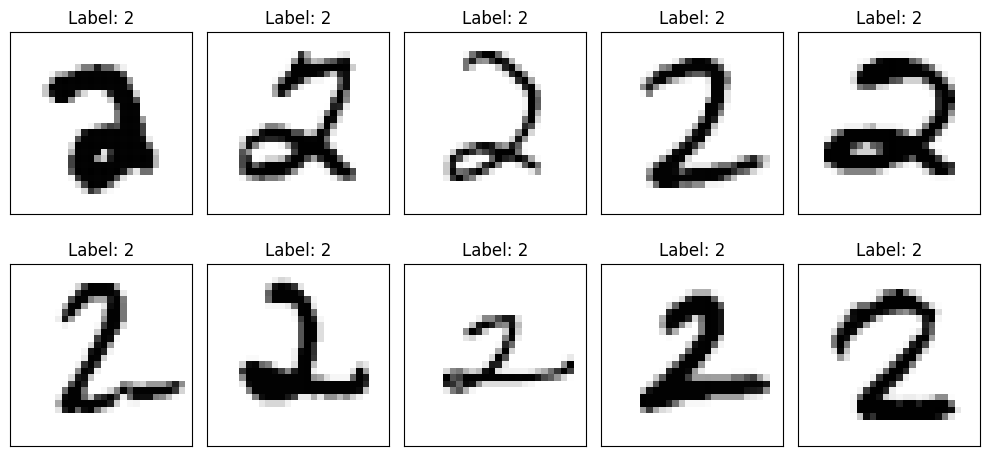

In [ ]:
fig , ax = plt.subplots(nrows=2,ncols=5,figsize = (10 , 5) , sharex = True , sharey = True)
ax_flat = ax.flatten()

# Correct way to get targets for a torch.utils.data.Subset
# validation_data.dataset refers to the original MNIST dataset
# validation_data.indices contains the indices of the original dataset that belong to the subset
target_subset = validation_data.dataset.targets[validation_data.indices]

# Get indices of all 2s within this filtered target tensor
indices_of_twos = (target_subset == 2).nonzero(as_tuple=True)[0]

# Ensure we only plot up to 10 images, and not more than available
num_images_to_plot = min(10, len(indices_of_twos))

for i in range(num_images_to_plot):
  # 'indices_of_twos[i].item()' gives the index of a '2' within the 'validation_data' subset
  # so validation_data[index_within_subset] correctly retrieves the image and label
  img , _ = validation_data[indices_of_twos[i].item()]
  pic = img.squeeze().reshape(28 , 28)
  label_text = str(int(_))
  ax_flat[i].imshow(pic , cmap = 'Greys')
  ax_flat[i].set_title(f'Label: {label_text}')
  ax_flat[i].set_xticks([])
  ax_flat[i].set_yticks([])

# Turn off any unused subplots if fewer than 10 images of '2' were found
for j in range(num_images_to_plot, 10):
    ax_flat[j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
loaders = [train_data_loader , validation_data_loader,test_data_laoder]
for loader in loaders:
  data_batch, target_batch = next(iter(loader)) # Get the first batch (data, target)
  print(f"\nBatch shape : {data_batch.shape} , {target_batch.shape}")


Batch shape : torch.Size([110, 1, 28, 28]) , torch.Size([110])

Batch shape : torch.Size([300, 1, 28, 28]) , torch.Size([300])

Batch shape : torch.Size([500, 1, 28, 28]) , torch.Size([500])


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [ ]:
## Create a custom mutli-layer perceptron using a Wide and deep NN architecture
class MNIST_CLASSIFIER(nn.Module):
    def __init__(self ,  n_inputs ,  n1 , n2 , n3):
        super().__init__()
        self.flatten = nn.Flatten()
        self.mlp = nn.Sequential(nn.Linear(n_inputs , n1), nn.ReLU(),
                                 nn.Linear(n1 , n2),nn.ReLU(),
                                 nn.Linear(n2 ,  n3),nn.ReLU())
        self.output = nn.Linear(n3 + n_inputs , 10 )

    def forward(self , x):
        x = self.flatten(x)
        deep_output = self.mlp(x)
        wide_and_deep = torch.concat([deep_output, x] , dim = 1) # --> While I was doing this I asked myself why it's torch and not tensor
        return self.output(wide_and_deep)

model = MNIST_CLASSIFIER(n_inputs = 784 ,  n1 = 571 , n2 = 442 , n3 = 363).to(device)

optimizer = optim.Adam(model.parameters(), lr = 0.00031489116479568613)
## Loss function
loss_function = nn.CrossEntropyLoss()
## Accuracy
metric_val = torchmetrics.Accuracy(task = 'multiclass' , num_classes = 10).to(device)
## Confirm model's parametres
print(next(model.parameters()).device)
print(model)

cpu
MNIST_CLASSIFIER(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (mlp): Sequential(
    (0): Linear(in_features=784, out_features=571, bias=True)
    (1): ReLU()
    (2): Linear(in_features=571, out_features=442, bias=True)
    (3): ReLU()
    (4): Linear(in_features=442, out_features=363, bias=True)
    (5): ReLU()
  )
  (output): Linear(in_features=1147, out_features=10, bias=True)
)


In [ ]:
torchinfo.summary(model , input_size = (110 , 1 , 28 , 28))

Layer (type:depth-idx)                   Output Shape              Param #
MNIST_CLASSIFIER                         [110, 10]                 --
├─Flatten: 1-1                           [110, 784]                --
├─Sequential: 1-2                        [110, 363]                --
│    └─Linear: 2-1                       [110, 571]                448,235
│    └─ReLU: 2-2                         [110, 571]                --
│    └─Linear: 2-3                       [110, 442]                252,824
│    └─ReLU: 2-4                         [110, 442]                --
│    └─Linear: 2-5                       [110, 363]                160,809
│    └─ReLU: 2-6                         [110, 363]                --
├─Linear: 1-3                            [110, 10]                 11,480
Total params: 873,348
Trainable params: 873,348
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 96.07
Input size (MB): 0.35
Forward/backward pass size (MB): 1.22
Params size (MB): 3.49
Estimated 

In [ ]:
def train_epoch( model , train_data , optimizer , device , loss_function , loss_history , epoch):
    model.train() # --> sets model to training mode
    loss_accumlation = 0 # --> Measusre loss
    print_interval = 100

    for batch_index , (data , target) in enumerate(train_data , 1):
        ## Ensure data is in same device
        data = data.to(device)
        ## Ensure target is in same device
        target = target.to(device)
        # foward prop
        y_pred = model(data)
        # calculate the loss
        loss = loss_function(y_pred , target)
        # backprop -- > the loss rep the loss function
        loss.backward()
        # Updates the parameters
        optimizer.step()
        # reset optimizers gradients
        optimizer.zero_grad()
        # trach progress , remember to multiply by batch size when the distribution of the batches is uneven
        loss_accumlation +=loss.item()
        loss_history[epoch] += loss_accumlation
        #Print 5 batches : Our data has 500 indices but we want to print the which provide this result batch_index % 100 == 0
        if batch_index % print_interval == 0 and batch_index < 0 :  # mean loss denominator is divided by print interval because it is the batch number , example we set print to be done after 100 batches meaning for 1 to 100 loss has been accumulating so average is just by the number of time sit is accumulating
            # Get the loss for training the model
            mean_loss = loss_accumlation / print_interval
            #print(f"\n[{batch_index * 110} /{55_000}] Loss : {mean_loss : .4f}\n")
            loss_accumlation = 0
        loss_history[epoch] /= len(train_data)
    return loss_history[epoch]

In [ ]:
def evaluation(model ,  device , data , metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for inputs , targets in data:
            inputs =  inputs.to(device)
            targets = targets.to(device)
            y_pred = model(inputs)
            metric.update(y_pred , targets)
    return metric.compute()


Fine tuning hyperparameters of model
using optuna.


In [ ]:
# Define a objective function
# In general,it’s much cleaner to pass them as extra arguments to the objective() function, for example, like this:
def objective(trial , train_epoch , evaluation):
  learning_rate = trial.suggest_float("learning_rate" , 1e-5 , 1e-1 , log = True)
  n_hidden = trial.suggest_int("n_hidden" ,   10 , 600)
  n_hidden2 = trial.suggest_int("n_hidden2" ,   10 , 600)
  n_hidden3 = trial.suggest_int("n_hidden3" ,   10 , 600)
  model = MNIST_CLASSIFIER(n_inputs = 784 ,  n1 = n_hidden , n2 = n_hidden2 , n3 = n_hidden3).to(device)
  optimizer = optim.Adam(model.parameters(), lr = learning_rate)
  loss_function = nn.CrossEntropyLoss()
  metric_val = torchmetrics.Accuracy(task = 'multiclass' , num_classes = 10).to(device)

  for epoch in range(8):
    train_epoch(model , train_data_loader , optimizer , device , loss_function)
    val_accuracy = evaluation(model , device , validation_data_loader , metric_val)
    trial.report(val_accuracy , epoch)
    if trial.should_prune():
      raise optuna.TrialPruned()
  return val_accuracy

In [ ]:
# To start hyper-par tuning we need to create a Study object and call it's optimize method
# passing it the objective function defined also number of trials
#By default, Optuna uses the Tree-structured Parzen Estimator (TPE) algorithm to
#optimize the hyperparameters: this is a sequential model-based optimization algorithm, meaning it learns from past results to better select promising hyperparameters.
#MedianPruner will prune trials whose performance is below the median performance at regular intervals during training
pruner = optuna.pruners.MedianPruner(n_startup_trials = 5, n_warmup_steps = 5, interval_steps = 1)
objective_with_data = lambda trial : objective(trial , train_epoch=train_epoch , evaluation=evaluation)
sampler = optuna.samplers.TPESampler(seed = 42)
#Since our objective function returns a score—higher is better—we set direction="maximize" when creating the study (by default, Optuna tries to minimize the objective).
study = optuna.create_study(direction = 'maximize' , sampler = sampler , pruner=pruner)
study.optimize(objective_with_data , n_trials = 7)

[I 2026-06-29 18:31:15,804] A new study created in memory with name: no-name-f22e9a52-3075-4428-95a3-db03e64821cf
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[I 2026-06-29 18:33:18,899] Trial 0 finished with value: 0.9769999980926514 and parameters: {'learning_rate': 0.00031489116479568613, 'n_hidden': 571, 'n_hidden2': 442, 'n_hidden3': 363}. Best is trial 0 with value: 0.9769999980926514.
[I 2026-06-29 18:34:46,034] Trial 1 finished with value: 0.920799970626831 and parameters: {'learning_rate': 4.207988669606632e-05, 'n_hidden': 102, 'n_hidden2': 44, 'n_hidden3': 521}. Best is trial 0 with value: 0.9769999980926514.
[I 2026-06-29 18:36:23,883] Trial 2 finished with value: 0.9746000170707703 and parameters: {'learning_rate': 0.002537815508265664, 'n_hidden': 428, 'n_hidden2': 22, 'n_hidden3': 583}. Best is t

**To implement the learning curves based on the example from Seba's book we need to store the loss based on an epoch . First create a list that will store the loss for 30 epochs **

In [ ]:
num_epochs = 20
loss_history = [0] * num_epochs
for epoch in range(num_epochs):
    print(f"\n--- Epoch {epoch + 1} ---")
    loss_history[epoch] = train_epoch(model , train_data_loader , optimizer , device , loss_function , loss_history , epoch)
    # Store the computed accuracy in a new variable to avoid overwriting the torchmetrics.Accuracy object
    current_epoch_accuracy = evaluation(model , device , validation_data_loader , metric_val)
    print(f"Test Accuracy : {current_epoch_accuracy : .2f}")


--- Epoch 1 ---


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Test Accuracy :  0.94

--- Epoch 2 ---
Test Accuracy :  0.96

--- Epoch 3 ---
Test Accuracy :  0.97

--- Epoch 4 ---
Test Accuracy :  0.97

--- Epoch 5 ---
Test Accuracy :  0.97

--- Epoch 6 ---
Test Accuracy :  0.97

--- Epoch 7 ---
Test Accuracy :  0.98

--- Epoch 8 ---
Test Accuracy :  0.98

--- Epoch 9 ---
Test Accuracy :  0.98

--- Epoch 10 ---
Test Accuracy :  0.98

--- Epoch 11 ---
Test Accuracy :  0.97

--- Epoch 12 ---
Test Accuracy :  0.98

--- Epoch 13 ---
Test Accuracy :  0.98

--- Epoch 14 ---
Test Accuracy :  0.98

--- Epoch 15 ---
Test Accuracy :  0.98

--- Epoch 16 ---
Test Accuracy :  0.98

--- Epoch 17 ---
Test Accuracy :  0.98

--- Epoch 18 ---
Test Accuracy :  0.98

--- Epoch 19 ---
Test Accuracy :  0.98

--- Epoch 20 ---
Test Accuracy :  0.98


In [ ]:
loss_history

[0.423071523138008,
 0.14798105781179913,
 0.10015934952725702,
 0.06885598198301962,
 0.05371102854120529,
 0.039695944727195655,
 0.0309552903509921,
 0.023618731706578116,
 0.018474349527955684,
 0.014867271923588296,
 0.014889020560880786,
 0.010178707809222722,
 0.009072081221685997,
 0.010482627309663968,
 0.007393466775625462,
 0.006761527898014125,
 0.006929989563079336,
 0.006628525785884489,
 0.005292918039340194,
 0.007861383394595195]

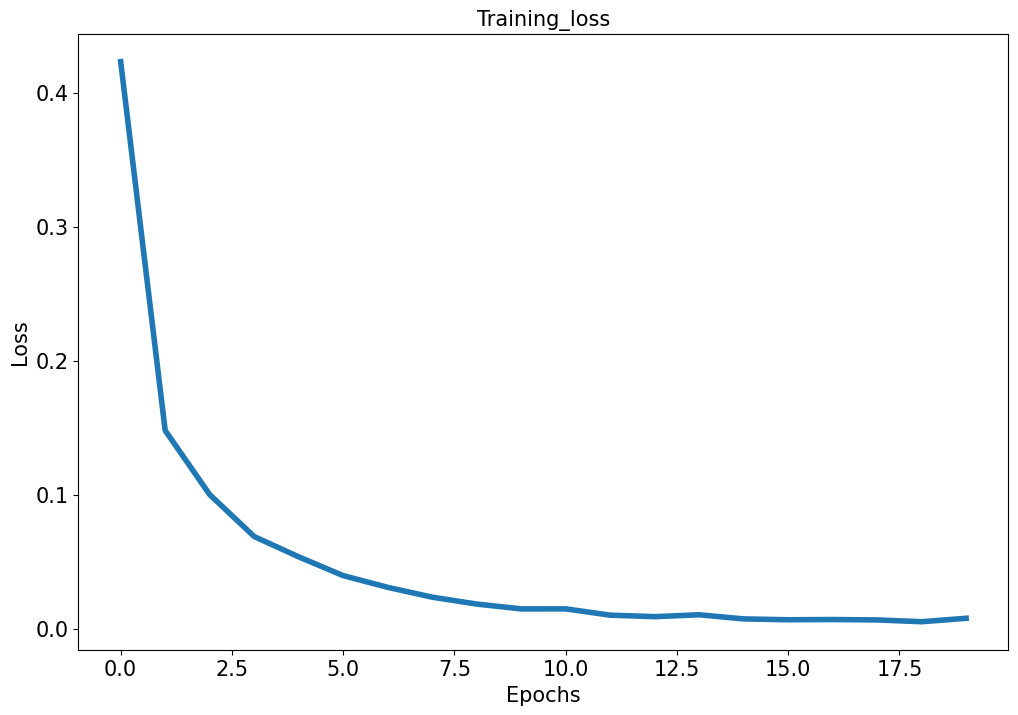

In [ ]:
## Visualize the loss function as it decreases
fig , ax = plt.subplots(1,1,figsize=(12,8))
ax.plot(loss_history ,  lw = 4)
ax.set_title("Training_loss" ,size = 15)
ax.set_xlabel("Epochs" , size = 15)
ax.set_ylabel("Loss" , size = 15)
ax.tick_params(axis = 'both' , which = 'major' , labelsize = 15)
plt.show()

In [ ]:
x = torch.tensor([[[2,2,2],[5,5,5]],[[3,3,3] , [4,4,4]]] , dtype = torch.float32)
means = x.mean(dim = 1 ,keepdims = True)
y = x.exp()
# conveert tensor to numpy array with numpy()
w = y.numpy()
# putting it in the format makes us access the first batch or channel
# This is a 3D tensor an doperates differently from a 2D tensor
x , x.shape , x[0 , 1] , y , w.shape ,means , means.shape

In [ ]:
a = torch.tensor([[2,2,2],[5,5,5],[3,3,3] , [4,4,4]] , dtype = torch.float32)
mean = a.mean(dim = 0 , keepdims = True)
a , a.shape , mean , mean.shape

In [ ]:
transform = transforms.Compose([
    T.ToImage(),

    T.ToDtype(torch.float32 , scale = True),
])

selected_classes = ['pushups', 'pullups', 'squats', 'lunges', 'plank']
train_dataset = datasets.HMDB51(root = 'HMDB51', annotation_path ='HMDB51_annotations', fold = 1, train = True ,transform  = transform , frames_per_clip = 16, num_workers = 4)

FileNotFoundError: [Errno 2] No such file or directory: 'HMDB51'

### Setting the Correct Path for Datasets in Colab

To resolve the `FileNotFoundError: [Errno 2] No such file or directory: 'HMDB51'`, you need to ensure that the HMDB51 dataset is present in your Colab environment and that the `root` argument in `datasets.HMDB51` points to its location.

Here are common ways to make datasets available in Colab and set their paths:

1.  **Downloading from a URL:** If the dataset is publicly available via a direct download link (e.g., a `.zip` or `.tar.gz` file), you can download and extract it within your Colab notebook using `!wget` or `!gdown` (for Google Drive hosted files).

    *Example for a hypothetical URL:*
    ```bash
    !wget -q YOUR_HMDB51_DATASET_URL.zip
    !unzip -q YOUR_HMDB51_DATASET_URL.zip -d HMDB51 # Extract to a directory named HMDB51
    ```

    *Then, your `root` path would be `root='HMDB51'` (if extracted to `/content/HMDB51`) or the specific path you extracted it to.*

2.  **Mounting Google Drive:** For larger datasets you've stored in your Google Drive, you can mount your Drive and then specify the path to the dataset.

    *Once mounted, your files are accessible under `/content/drive/MyDrive/`. So, if you have an `HMDB51` folder in your Drive, the path would be `root='/content/drive/MyDrive/HMDB51'`.*

3.  **Manual Upload (less common for large datasets):** For very small datasets, you can manually upload them through the Colab file browser, but this is not practical for large video datasets like HMDB51.

**For HMDB51 specifically:**

*   You will need to acquire the HMDB51 dataset files. This usually involves downloading them from a research website (e.g., [https://serre-lab.clps.brown.edu/resource/hmdb-a-large-human-motion-database/](https://serre-lab.clps.brown.edu/resource/hmdb-a-large-human-motion-database/)) and then either uploading them to your Google Drive or a cloud storage service, or using a direct download link if available and permitted.
*   Once you have the dataset, ensure its structure matches what `torchvision.datasets.HMDB51` expects (typically a root directory containing subdirectories for each action class, along with the annotation files).

In [ ]:
# Example of how to mount Google Drive and prepare a directory
from google.colab import drive
import os

# 1. Mount Google Drive (if your dataset is there)
drive.mount('/content/drive')

# 2. Define the path where your HMDB51 dataset is located or will be extracted
#    If you downloaded and extracted it to /content/HMDB51:
# dataset_root = 'HMDB51'

#    If you put it in your Google Drive, for example, under 'My Drive/Datasets/HMDB51_data':
dataset_root = '/content/drive/MyDrive/Datasets/HMDB51_data'

#    Ensure the directory exists. If you're going to download and extract, you might create it first.
if not os.path.exists(dataset_root):
    print(f"Creating directory: {dataset_root}")
    os.makedirs(dataset_root)

# Now, you would use 'dataset_root' in your HMDB51 constructor
# For example (assuming HMDB51 data is correctly placed inside this root):
# train_dataset = datasets.HMDB51(root=dataset_root, annotation_path='HMDB51_annotations', fold=1, train=True, transform=transform, frames_per_clip=16, num_workers=4)
# print(f"Dataset root set to: {dataset_root}")

print(f"Make sure your HMDB51 dataset files (including the annotation_path) are located within: {dataset_root}")

MessageError: Error: credential propagation was unsuccessful